In [1]:
import numpy as np
import matplotlib.pyplot as plt

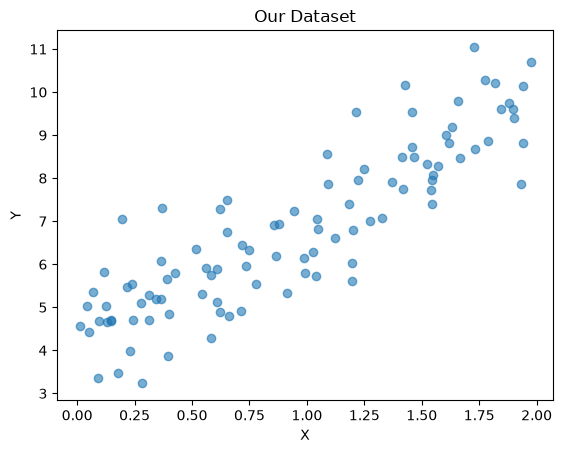

In [2]:
# Simple synthetic dataset
np.random.seed(42)
X = 2 * np.random.rand(100,1)
y = 4 + 3 * X + np.random.randn(100,1)

plt.scatter(X, y, alpha=0.6)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Our Dataset')
plt.show()


In [3]:
# implementing cost function
def compute_cost(X, y, theta0, theta1):
    m = len(y)
    predictions = theta0 + theta1 * X
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    return cost

# Testing with some values
print(compute_cost(X, y, theta0=0, theta1=0))
print(compute_cost(X,y, theta0=4, theta1=3))


25.00415182181856
0.4125533899539692


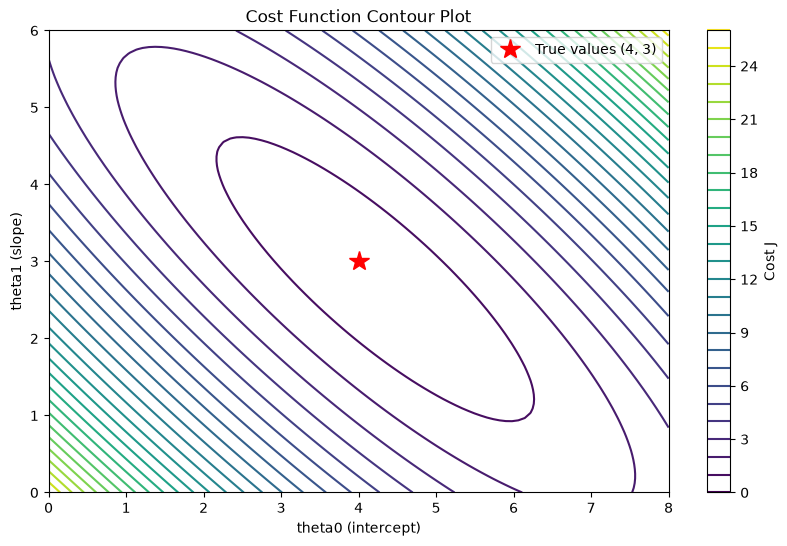

In [4]:
# visualising the cost function(contour plot)

theta0_vals = np.linspace(0, 8, 100)
theta1_vals = np.linspace(0, 6, 100)

J_vals = np.zeros((len(theta0_vals), len(theta1_vals)))

for i, t0 in enumerate(theta0_vals):
    for j, t1 in enumerate(theta1_vals):
        J_vals[i, j] = compute_cost(X, y, t0, t1)

plt.figure(figsize=(10, 6))
plt.contour(theta0_vals, theta1_vals, J_vals.T, levels=30, cmap='viridis')
plt.colorbar(label='Cost J')
plt.xlabel('theta0 (intercept)')
plt.ylabel('theta1 (slope)')
plt.title('Cost Function Contour Plot')
plt.plot(4, 3, 'r*', markersize=15, label='True values (4, 3)')
plt.legend()
plt.show()

In [5]:
# Add bias term (column of 1s) to X
X_b = np.c_[np.ones((100, 1)), X]

# Normal Equation 
theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)

print("theta0 (intercept):", theta_best[0])
print("theta1 (slope):", theta_best[1])

theta0 (intercept): [4.21509616]
theta1 (slope): [2.77011339]


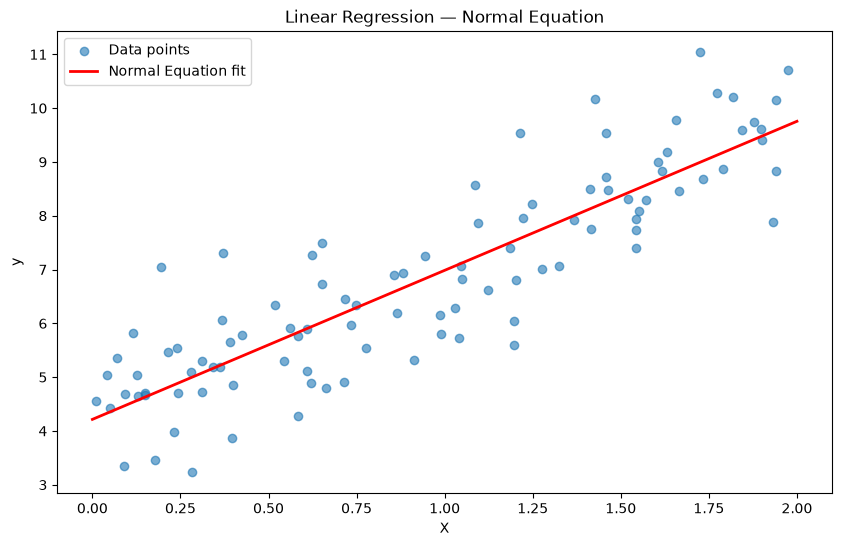

In [6]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b.dot(theta_best)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.6, label='Data points')
plt.plot(X_new, y_predict, 'r-', linewidth=2, label='Normal Equation fit')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Linear Regression — Normal Equation')
plt.legend()
plt.show()

### **Gradient Descent from Scratch:**

In [7]:

class GradientDescent:

    def __init__(self, learning_rate=0.01, epochs=1000, verbose=True, verbose_every=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.verbose = verbose
        self.verbose_every = verbose_every

        # These get set during training
        self.weights = None      # θ1, θ2, ... θn (slopes)
        self.bias = None         # θ0 (intercept)
        self.cost_history = []   # track cost per epoch
        self.weight_history = [] # track weights per epoch

    def fit(self, X, y):
        """
        X : feature matrix - shape (m, n) - m samples, n features
        y : number of features
        
        """
        m, n = X.shape
        # m = number of training examples
        # n = number of features

        # -- INITIALIZATION --
        # Random initialization of weight and bias
        self.weights = np.random.randn(n,1) * 0.01
        self.bias = np.zeros((1,1))

        # Initial shapes:
        # X.shape      → (m, n)   e.g. (100, 1) for single feature
        # y.shape      → (m, 1)   e.g. (100, 1)
        # weights.shape → (n, 1)  e.g. (1, 1) for single feature
        # bias.shape   → (1, 1)

        if self.verbose:
            print(f"Training started:")
            print(f" X shape: {X.shape}")
            print(f" y shape: {y.shape}")
            print(f" weights shape: {self.weights.shape}")
            print(f" bias shape: {self.bias.shape}")
            print(f" Initial weights: {self.weights.flatten()}")
            print(f" Initial bias: {self.bias.flatten()}")
            print()
            print("*" * 50)

        # -- Training loop --
        for epoch in range(self.epochs):

            # -- Forward Pass --
            predictions = X.dot(self.weights) + self.bias

            # errors
            errors = predictions - y

            # cost
            cost = (1/(2 * m) * np.sum(errors ** 2))
            self.cost_history.append(cost)

            # compute gradients
            dw  = (1 / m) * X.T.dot(errors)
            db = (1 / m) * np.sum(errors)

            # updating the parameters
            self.weights = self.weights - self.learning_rate * dw
            self.bias = self.bias - self.learning_rate * db

            # tracking the weight history
            self.weight_history.append({
                'epoch' : epoch,
                'weights' : self.weights.copy().flatten(),
                'bias' : self.bias.copy().flatten()[0],
                'cost' : cost
            })

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs}")
                print (f"Cost: {cost:.6f}")
                print (f"Weights: {self.weights.flatten()}")
                print (f"Bias: {self.bias.flatten()[0]:.4f}")
                print()

        if self.verbose:
            print("-" * 50)
            print(f"Training complete!")
            print(f"  Final weights: {self.weights.flatten()}")
            print(f"  Final bias: {self.bias.flatten()[0]:.4f}")

        return self

    def predict(self, X):
        return X.dot(self.weights) + self.bias

    def score(self, X, y):
        predictions = self.predict(X)
        ss_res = np.sum((y - predictions) ** 2)
        ss_total = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_res / ss_total)

    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'b-')
        plt.xlabel('Epoch')
        plt.ylabel('Cost (MSE)')
        plt.title('Cost history')
        plt.grid(True)
        plt.show()

    def plot_weight_evolution(self, true_weights=None, true_bias=None):
        epochs = [h['epoch'] for h in self.weight_history]
        biases = [h['bias'] for h in self.weight_history]
        
        n_weights = len(self.weight_history[0]['weights'])
        
        # Plot each weight separately
        fig, axes = plt.subplots(2, (n_weights + 1) // 2 + 1, 
                                  figsize=(18, 8))
        axes = axes.flatten()
        
        for i in range(n_weights):
            weights_i = [h['weights'][i] for h in self.weight_history]
            axes[i].plot(epochs, weights_i, 'r-')
            axes[i].set_title(f'Weight {i+1} (θ{i+1})')
            axes[i].set_xlabel('Epoch')
            axes[i].set_ylabel(f'θ{i+1}')
            axes[i].grid(True)
            
            # Only plot true value if provided
            if true_weights is not None:
                axes[i].axhline(y=true_weights[i], color='g', 
                               linestyle='--', 
                               label=f'Sklearn value ({true_weights[i]:.2f})')
                axes[i].legend(fontsize=7)
        
        # Plot bias separately
        axes[n_weights].plot(epochs, biases, 'b-')
        axes[n_weights].set_title('Bias (θ0)')
        axes[n_weights].set_xlabel('Epoch')
        axes[n_weights].set_ylabel('θ0')
        axes[n_weights].grid(True)
        
        if true_bias is not None:
            axes[n_weights].axhline(y=true_bias, color='g', 
                                   linestyle='--',
                                   label=f'Sklearn value ({true_bias:.2f})')
            axes[n_weights].legend(fontsize=7)
        
        # Hide empty subplots
        for j in range(n_weights + 1, len(axes)):
            axes[j].set_visible(False)
        
        plt.suptitle('Weight Evolution During Training', fontsize=14)
        plt.tight_layout()
        plt.show()

In [8]:
model = GradientDescent(0.1, 100, True, 100)
model.fit(X,y)

Training started:
 X shape: (100, 1)
 y shape: (100, 1)
 weights shape: (1, 1)
 bias shape: (1, 1)
 Initial weights: [0.00013002]
 Initial bias: [0.]

**************************************************
Epoch    0/100
Cost: 25.003192
Weights: [0.73852222]
Bias: 0.6820

--------------------------------------------------
Training complete!
  Final weights: [2.92862164]
  Final bias: 4.0356


In [9]:
model.score(X,y)

np.float64(0.7664892391572748)

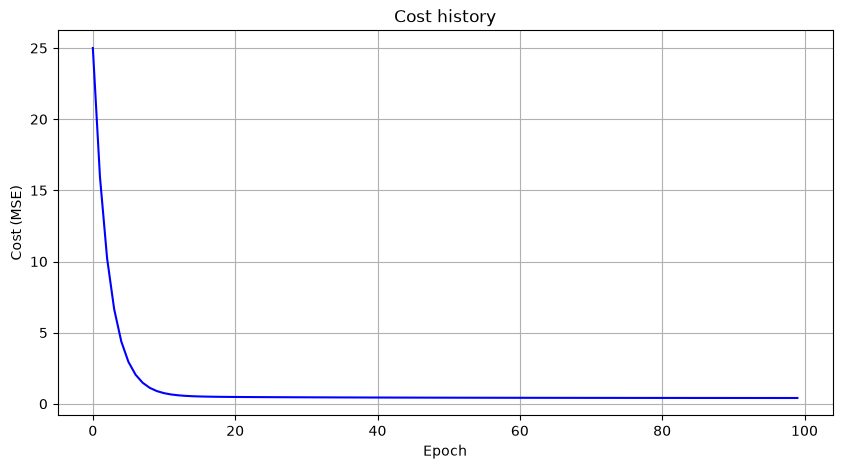

In [10]:
model.plot_cost_history()

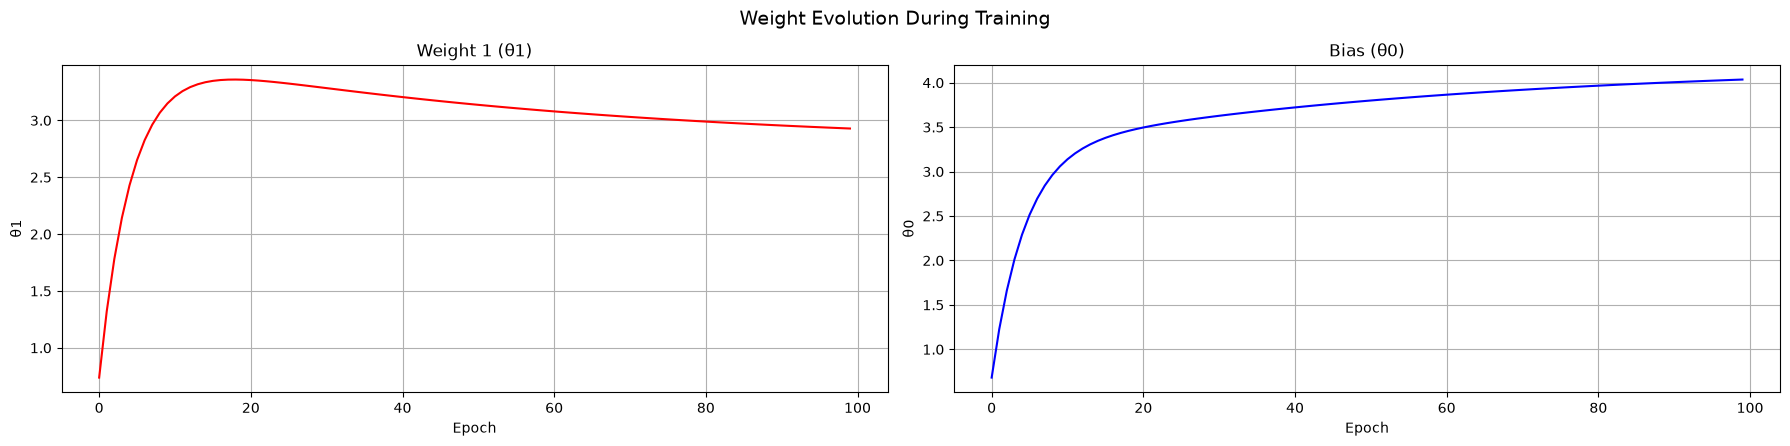

In [11]:
model.plot_weight_evolution()

#### **Now let's generate a 10-feature dataset and run everything again**

In [12]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Generate dataset with 10 features
X_multi, y_multi = make_regression(
    n_samples=500,
    n_features=10,
    noise=10,
    random_state=42
)

# Reshape y to column vector
y_multi = y_multi.reshape(-1, 1)

print("X_multi shape:", X_multi.shape)
print("y_multi shape:", y_multi.shape)

X_multi shape: (500, 10)
y_multi shape: (500, 1)


In [13]:
scaler = StandardScaler()
X_multi_scaled = scaler.fit_transform(X_multi)

print("Mean after scaling:", X_multi_scaled.mean(axis=0).round(4))
print("Std after scaling:", X_multi_scaled.std(axis=0).round(4))

Mean after scaling: [-0.  0.  0. -0. -0.  0.  0. -0.  0. -0.]
Std after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [14]:
sk_model = LinearRegression()
sk_model.fit(X_multi_scaled, y_multi)

print("Sklearn coefficients:", sk_model.coef_.flatten().round(4))
print("Sklearn intercept:", sk_model.intercept_[0].round(4))
print("Sklearn R²:", sk_model.score(X_multi_scaled, y_multi))

Sklearn coefficients: [39.455  63.9095 19.855  46.9219 24.4365 15.706  82.9567 66.832   7.1515
 28.5014]
Sklearn intercept: -1.587
Sklearn R²: 0.9956312742196273


In [15]:
gd_model = GradientDescent(
    learning_rate=0.01,
    epochs=500,
    verbose=True,
    verbose_every=100
)

gd_model.fit(X_multi_scaled, y_multi)

Training started:
 X shape: (500, 10)
 y shape: (500, 1)
 weights shape: (10, 1)
 bias shape: (1, 1)
 Initial weights: [ 0.01453534 -0.00264657  0.02720169  0.00625667 -0.00857158 -0.01070892
  0.00482472 -0.00223463  0.00714     0.00473238]
 Initial bias: [0.]

**************************************************
Epoch    0/500
Cost: 10559.509809
Weights: [0.46753437 0.56193252 0.21499014 0.44169306 0.26976019 0.09950941
 0.87148063 0.64812699 0.04731181 0.28406237]
Bias: -0.0159

Epoch  100/500
Cost: 1490.325176
Weights: [27.32193682 37.89275866 12.08333942 28.70542059 16.84966459  8.3280684
 54.19627902 41.77410782  3.19978164 17.83708498]
Bias: -1.0119

Epoch  200/500
Cost: 250.638256
Weights: [35.81301001 53.26097953 16.63964465 39.82743343 22.14182481 12.42329829
 72.84858996 57.22530491  5.05834464 24.38419127]
Bias: -1.3765

Epoch  300/500
Cost: 75.990122
Weights: [38.43252352 59.55737776 18.47647844 44.1691925  23.78592377 14.29624879
 79.39231005 63.10582294  6.0901379  26.8832

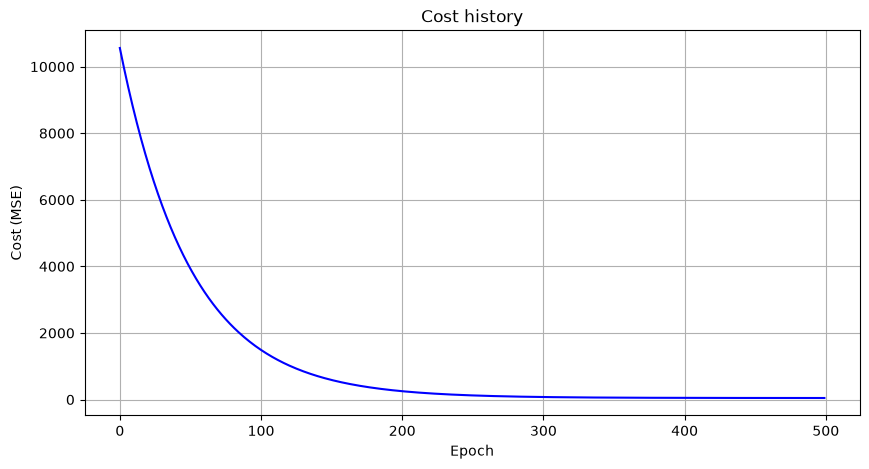

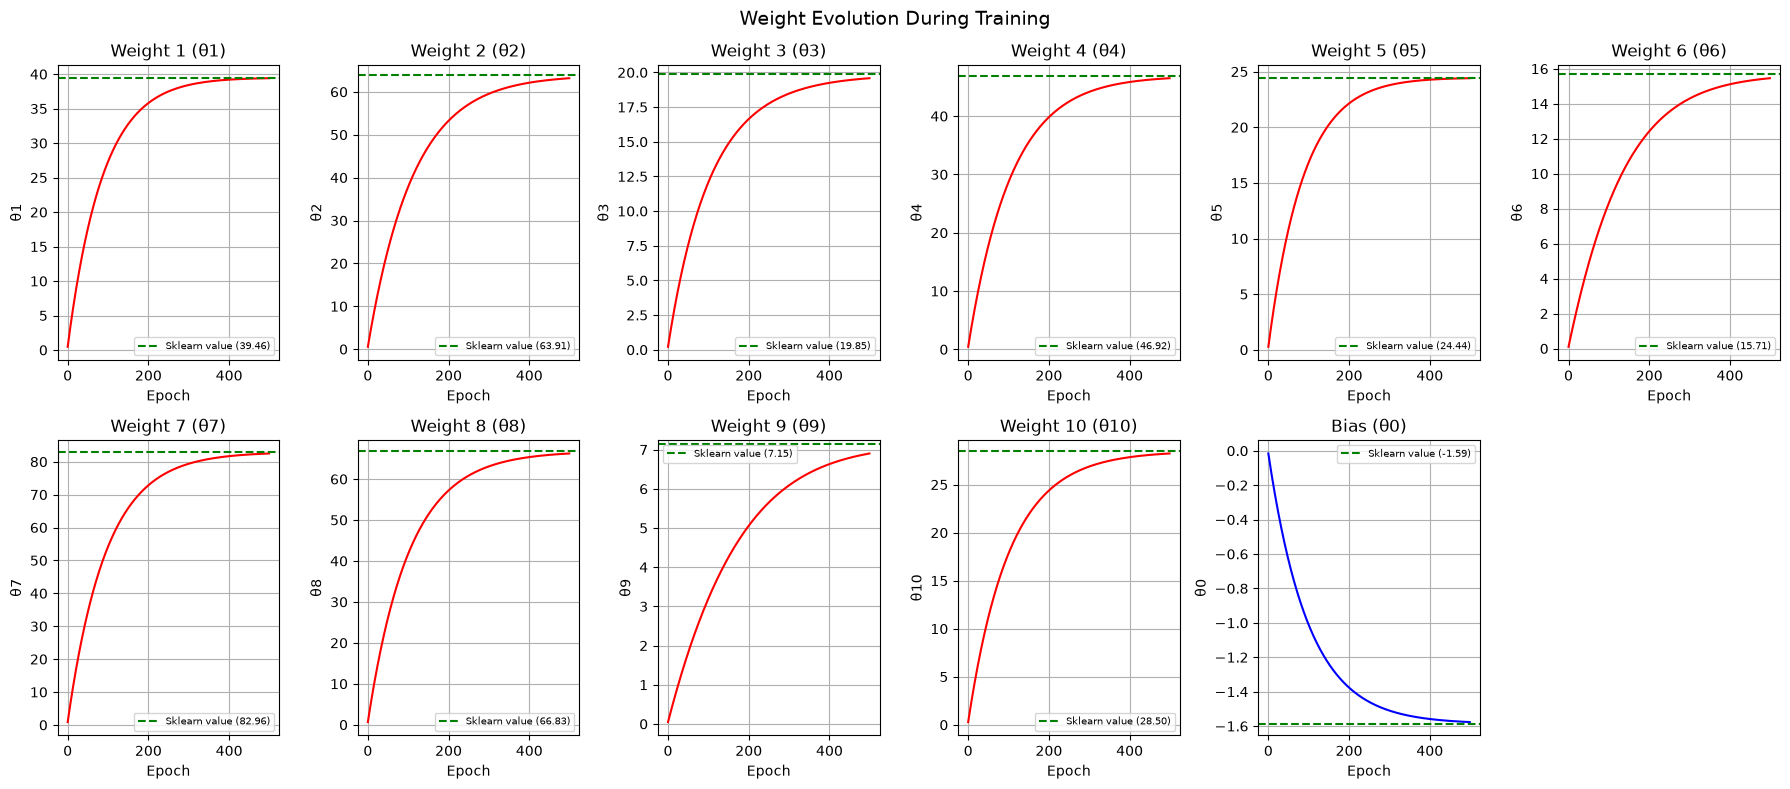

In [16]:
gd_model.plot_cost_history()
gd_model.plot_weight_evolution(
    true_weights=sk_model.coef_.flatten(),
    true_bias=sk_model.intercept_[0]
)

In [17]:
print("Sklearn weights:        ", sk_model.coef_.flatten().round(4))
print("Gradient Descent weights:", gd_model.weights.flatten().round(4))
print()
print("Sklearn bias:        ", round(sk_model.intercept_[0], 4))
print("Gradient Descent bias:", round(gd_model.bias[0][0], 4))
print()
print("Sklearn R²:          ", round(sk_model.score(X_multi_scaled, y_multi), 4))
print("Gradient Descent R²: ", round(gd_model.score(X_multi_scaled, y_multi), 4))

Sklearn weights:         [39.455  63.9095 19.855  46.9219 24.4365 15.706  82.9567 66.832   7.1515
 28.5014]
Gradient Descent weights: [39.4144 63.1754 19.5819 46.5048 24.4078 15.459  82.5038 66.2481  6.9019
 28.2384]

Sklearn bias:         -1.587
Gradient Descent bias: -1.5765

Sklearn R²:           0.9956
Gradient Descent R²:  0.9956


### Stochastic Gradient Descent

In [18]:
class SGD:

    def __init__(self, learning_rate=0.01, epochs=100, verbose=True, verbose_every=10):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n, 1) * 0.01
        self.bias = np.zeros((1,1))

        if self.verbose:
            print(f"Training started:")
            print(f" X shape: {X.shape}")
            print(f" y shape: {y.shape}")
            print(f" weights shape: {self.weights.shape}")
            print(f" Initial weights: {self.weights.flatten()}")
            print(f" Initial bias: {self.bias.flatten()}")
            print("\n")
            print("-" * 50)

        for epoch in range(self.epochs):
            
            # Shuffle data at start of each epoch
            # prevents model from learning order of samples
            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            y_shuffled = y[indices]
            
            epoch_cost = 0
            
            for i in range(m):

                xi = X_shuffled[i].reshape(1, -1)
                yi = y_shuffled[i].reshape(1, -1)

                predictions = xi.dot(self.weights) + self.bias
                error = predictions - yi
                dw = xi.T.dot(error)
                db = np.sum(error)

                self.weights = self.weights - self.learning_rate * dw
                self.bias = self.bias - self.learning_rate * db

                epoch_cost += (1/2) * np.sum(error ** 2)
                
            epoch_cost /= m
            self.cost_history.append(epoch_cost)

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs}")
                print(f"Cost: {epoch_cost:.6f}")
                print(f"Weights: {self.weights.flatten().round(4)}")
                print(f"Bias: {self.bias.flatten()[0]:.4f}")
                print()

        if self.verbose:
            print("-" * 50)
            print(f"Training complete!")
            print(f"  Final weights: {self.weights.flatten().round(4)}")
            print(f"  Final bias: {self.bias.flatten()[0]:.4f}")
        
        return self

    def predict(self, X):
        return X.dot(self.weights) + self.bias
    
    def score(self, X, y):
        predictions = self.predict(X)
        ss_res = np.sum((y - predictions) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_res / ss_tot)
    
    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'b-')
        plt.xlabel('Epoch')
        plt.ylabel('Cost (MSE)')
        plt.title('Cost History — SGD')
        plt.grid(True)
        plt.show()


In [19]:
sgd_model = SGD(
    learning_rate=0.01,
    epochs=100,
    verbose=True,
    verbose_every=10
)

sgd_model.fit(X_multi_scaled, y_multi)

Training started:
 X shape: (500, 10)
 y shape: (500, 1)
 weights shape: (10, 1)
 Initial weights: [-0.00072829 -0.00846794 -0.01514847 -0.00446515  0.00856399  0.00214094
 -0.01245739  0.00173181  0.00385317 -0.00883857]
 Initial bias: [0.]


--------------------------------------------------
Epoch    0/100
Cost: 1182.593834
Weights: [39.9652 63.1045 20.6018 46.2716 24.8476 15.7946 82.9038 66.2455  7.3894
 26.5546]
Bias: -1.7332

Epoch   10/100
Cost: 48.923675
Weights: [38.947  64.5998 19.229  45.6803 23.4068 16.1627 82.6824 67.7137  5.9071
 28.9624]
Bias: -1.5898

Epoch   20/100
Cost: 50.646572
Weights: [38.5944 63.482  20.1313 46.7163 24.875  16.0275 83.8245 66.9547  6.8375
 28.4879]
Bias: -1.7157

Epoch   30/100
Cost: 49.191610
Weights: [38.7849 63.6201 20.295  47.0186 25.1985 16.3188 82.9618 66.9488  8.0145
 27.2486]
Bias: -1.3653

Epoch   40/100
Cost: 49.608716
Weights: [38.5068 64.0577 19.7984 46.8412 25.4331 16.874  83.3005 66.8409  6.0385
 28.4831]
Bias: -1.9398

Epoch   50/10

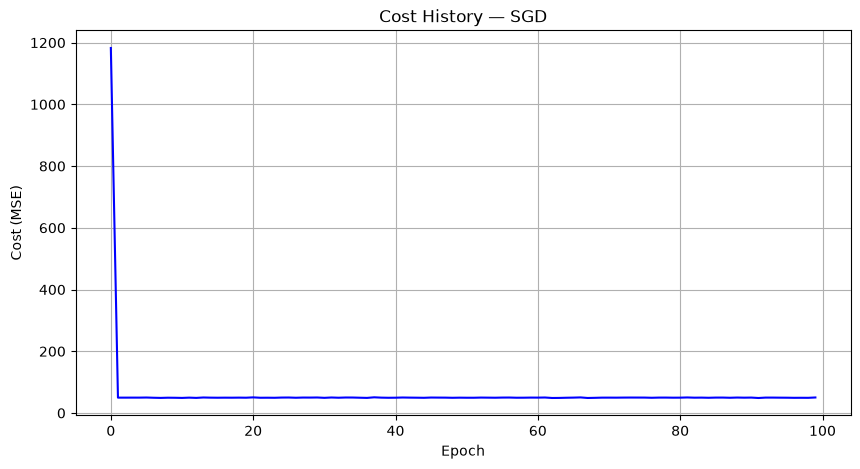

In [20]:
sgd_model.plot_cost_history()

In [21]:
print("=" * 60)
print("COMPARISON — Sklearn vs Batch GD vs SGD")
print("=" * 60)
print(f"Sklearn R²:    {sk_model.score(X_multi_scaled, y_multi):.4f}")
print(f"Batch GD R²:   {gd_model.score(X_multi_scaled, y_multi):.4f}")
print(f"SGD R²:        {sgd_model.score(X_multi_scaled, y_multi):.4f}")

COMPARISON — Sklearn vs Batch GD vs SGD
Sklearn R²:    0.9956
Batch GD R²:   0.9956
SGD R²:        0.9955


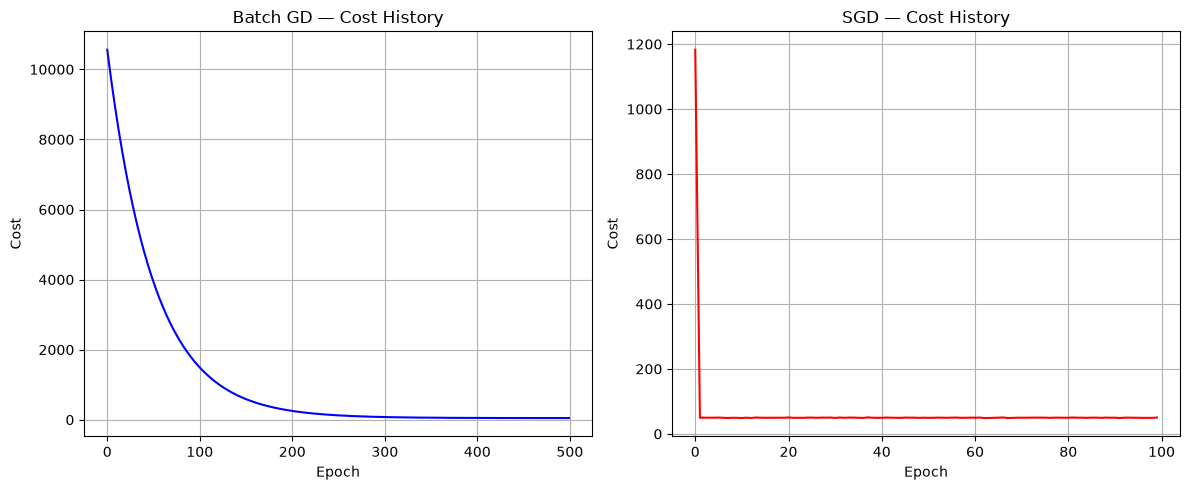

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(gd_model.epochs), gd_model.cost_history, 'b-')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Batch GD — Cost History')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(sgd_model.epochs), sgd_model.cost_history, 'r-')
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('SGD — Cost History')
plt.grid(True)

plt.tight_layout()
plt.show()

### Mini-Batch Gradient Descent

In [23]:
class MiniBatchGD:
    def __init__(self, learning_rate=0.01, epochs=100, batch_size=32, verbose=True, verbose_every=10):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose
        self.verbose_every = verbose_every

        self.weights = None
        self.bias = None
        self.cost_history = []

    def fit(self, X, y):
        m, n = X.shape

        self.weights = np.random.randn(n, 1) * 0.01
        self.bias = np.zeros((1,1))

        if self.verbose:
            print(f"Training started:")
            print(f" X shape: {X.shape}")
            print(f" y shape: {y.shape}")
            print(f" weight shape: {self.weights.shape}")
            print(f" batch size: {self.batch_size}")
            print(f" batches per epoch: {m // self.batch_size} ")
            print(f" Initial weights: {self.weights.flatten()}")
            print(f" Initial bias: {self.bias.flatten()}")
            print()
            print("-" * 50)

        for epoch in range(self.epochs):

            indices = np.random.permutation(m)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_cost = 0
            n_batches = 0

            for start in range(0, m, self.batch_size):

                X_batch = X_shuffled[start: start + self.batch_size]
                y_batch = y_shuffled[start: start + self.batch_size]

                batch_m = len(X_batch)

                predictions = X_batch.dot(self.weights) + self.bias

                errors = predictions - y_batch

                dw = (1 / batch_m) * X_batch.T.dot(errors)
                db = (1 / batch_m) * np.sum(errors)

                self.weights = self.weights - self.learning_rate * dw
                self.bias = self.bias - self.learning_rate * db

                epoch_cost += (1 / (2 * batch_m)) * np.sum(errors ** 2)
                n_batches += 1

            epoch_cost /= n_batches
            self.cost_history.append(epoch_cost)

            if self.verbose and epoch % self.verbose_every == 0:
                print(f"Epoch {epoch:4d}/{self.epochs}")
                print(f"Cost: {epoch_cost:.6f}")
                print(f"Weights: {self.weights.flatten().round(4)}")
                print(f"Bias: {self.bias.flatten()[0]}")
                print()

        if self.verbose:
            print("-" * 50)
            print(f"Training complete!")
            print(f" Final weights: {self.weights.flatten().round(4)}")
            print(f" Final bias: {self.bias.flatten()[0]:.4f}")
            
        return self

    def predict(self, X):
        return X.dot(self.weights) + self.bias
    
    def score(self, X, y):
        predictions = self.predict(X)
        ss_res = np.sum((y - predictions) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        return 1 - (ss_res / ss_tot)
    
    def plot_cost_history(self):
        plt.figure(figsize=(10, 5))
        plt.plot(range(self.epochs), self.cost_history, 'g-')
        plt.xlabel('Epoch')
        plt.ylabel('Cost (MSE)')
        plt.title('Cost History — Mini-batch GD')
        plt.grid(True)
        plt.show()
        


Training started:
 X shape: (500, 10)
 y shape: (500, 1)
 weight shape: (10, 1)
 batch size: 32
 batches per epoch: 15 
 Initial weights: [ 0.00153725  0.01103436  0.00427881  0.01813967  0.0241828   0.00017994
  0.00957308  0.02368528 -0.00617602 -0.02787356]
 Initial bias: [0.]

--------------------------------------------------
Epoch    0/100
Cost: 9115.865181
Weights: [ 6.6777  8.346   2.992   6.6295  4.0371  1.7623 12.7486  9.6033  0.6491
  4.0962]
Bias: -0.25547536618333067

Epoch   10/100
Cost: 439.868878
Weights: [34.517  50.562  15.9206 38.0055 21.3772 11.6335 69.9126 54.655   4.618
 23.2548]
Bias: -1.30330274420554

Epoch   20/100
Cost: 63.837881
Weights: [38.8133 60.7526 18.8609 45.0038 24.0194 14.6205 80.4965 64.1796  6.319
 27.3318]
Bias: -1.5142357082926066

Epoch   30/100
Cost: 47.550418
Weights: [39.4122 63.1629 19.5844 46.4917 24.4052 15.4497 82.4961 66.2595  6.8685
 28.2295]
Bias: -1.5723401511117265

Epoch   40/100
Cost: 46.181975
Weights: [39.4658 63.7263 19.7785 46

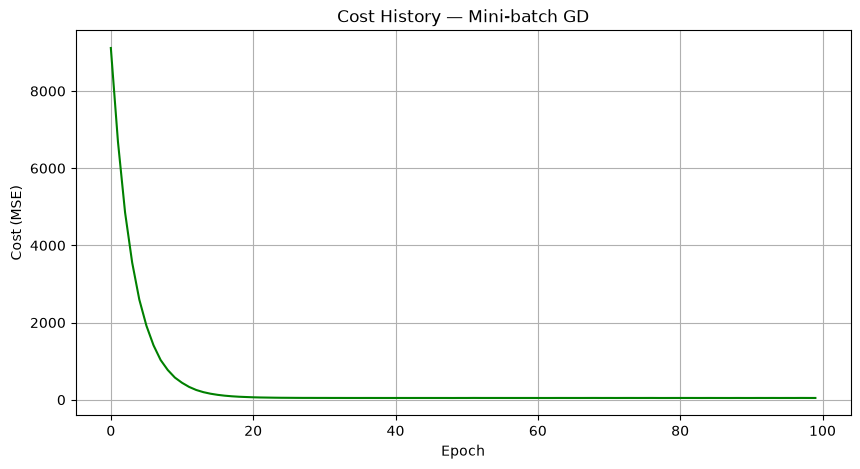

In [24]:
mb_model = MiniBatchGD(
    learning_rate=0.01,
    epochs=100,
    batch_size=32,
    verbose=True,
    verbose_every=10
)

mb_model.fit(X_multi_scaled, y_multi)
mb_model.plot_cost_history()

In [25]:
print("=" * 60)
print("FINAL COMPARISON — All Methods")
print("=" * 60)
print(f"Sklearn R²:         {sk_model.score(X_multi_scaled, y_multi):.4f}")
print(f"Batch GD R²:        {gd_model.score(X_multi_scaled, y_multi):.4f}")
print(f"SGD R²:             {sgd_model.score(X_multi_scaled, y_multi):.4f}")
print(f"Mini-batch GD R²:   {mb_model.score(X_multi_scaled, y_multi):.4f}")

FINAL COMPARISON — All Methods
Sklearn R²:         0.9956
Batch GD R²:        0.9956
SGD R²:             0.9955
Mini-batch GD R²:   0.9956
